# SE(2): expressing a point in different coordinate frames

This notebook uses the `SE2` and `SO2` classes from `robotics_toolbox.core`, i.e. it needs your HW01 implementation of `so2.py` and `se2.py` to work.

## The scene

Everything is drawn on a unit grid. The grid is only a drawing aid, we never use its coordinates; all quantities are read off *relative* to the frames.

| frame / point | where | axes |
|---|---|---|
| $A$ | at the grid origin, rotated $90^\circ$ | $x_A$ up, $y_A$ left |
| $B$ | 2 squares right and 1 square up of $A$, rotated $45^\circ$ | $x_B$ top-right, $y_B$ top-left |
| $P$ | 3 squares right of $A$ | – |

**Task:** we know the coordinates of $P$ in frame $B$ and we want its coordinates in frame $A$.

## Notation

An SE(2) transformation is a rotation $R \in SO(2)$ and a translation $t \in \mathbb{R}^2$, usually written as a $3\times3$ homogeneous matrix (SE(3) would be $4\times4$)

$$
T = \begin{bmatrix} R & t \\ 0 & 1 \end{bmatrix}, \qquad
R(\theta) = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix} .
$$

In the toolbox this is `SE2(translation=t, rotation=SO2(theta))`; `.homogeneous()` returns the matrix, `.act(p)` applies the transformation to a point and `*` composes two transformations.

We write $T_{AB}$ for the **pose of frame $B$ expressed in frame $A$**: its translation $t_{AB}$ is the vector from the origin of $A$ to the origin of $B$ (in $A$'s coordinates) and its rotation $R_{AB}$ rotates the axes of $A$ onto the axes of $B$.

The same transformation **maps coordinates of a point from $B$ to $A$**:

$$ p_A = T_{AB}\, p_B \qquad\text{i.e.}\qquad \texttt{p\_A = T\_AB.act(p\_B)} . $$

Read the subscripts as "target, source". This makes chaining consistent: $T_{AC} = T_{AB}\, T_{BC}$ (inner indices cancel), in code `T_AC = T_AB * T_BC`.

So: the transformation we *construct* geometrically by going from $A$ to $B$ is $T_{AB}$, and it is exactly the one we *apply* to move $P$'s coordinates from $B$ to $A$.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from robotics_toolbox.core import SE2, SO2

# drawing helpers (not important for the math), see se2_frames_plot.py next to this notebook
from se2_frames_plot import COLORS, deg, draw_angle, draw_frame, draw_point, draw_projection, draw_vector, new_axes

np.set_printoptions(precision=3, suppress=True)

## Step 1: draw the scene

To draw, we need to place the frames and the point on the grid. These grid poses are used **only for drawing**; the computation below never touches them.

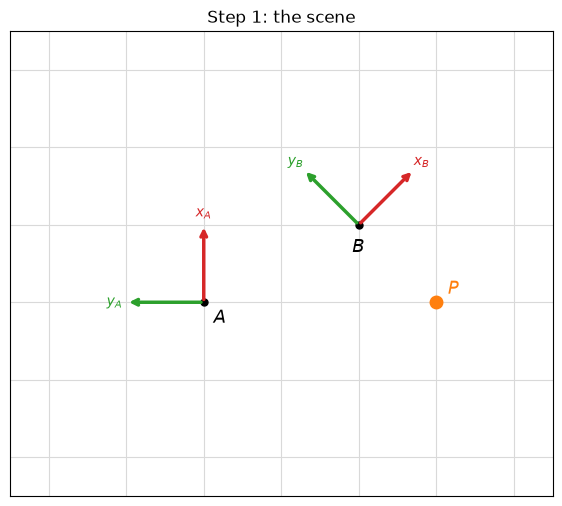

In [8]:
pose_A = SE2(translation=[0.0, 0.0], rotation=SO2(np.deg2rad(90)))  # drawing only
pose_B = SE2(translation=[2.0, 1.0], rotation=SO2(np.deg2rad(45)))  # drawing only
P = np.array([3.0, 0.0])  # grid position of P, drawing only

fig, ax = new_axes("Step 1: the scene")
draw_frame(ax, pose_A, "A")
draw_frame(ax, pose_B, "B")
draw_point(ax, P)
plt.show()

## Step 2: the point $P$ in frame $B$

Read the coordinates of $P$ in $B$ off the drawing. From the origin of $B$, the point $P$ is one square to the right and one square down. That is the direction bottom-right, i.e. exactly $-y_B$, and the length of the diagonal of a unit square is $\sqrt2$. Hence

$$ P_B = (0, -\sqrt2) \approx (0, -1.414). $$

P_B = [ 0.    -1.414]


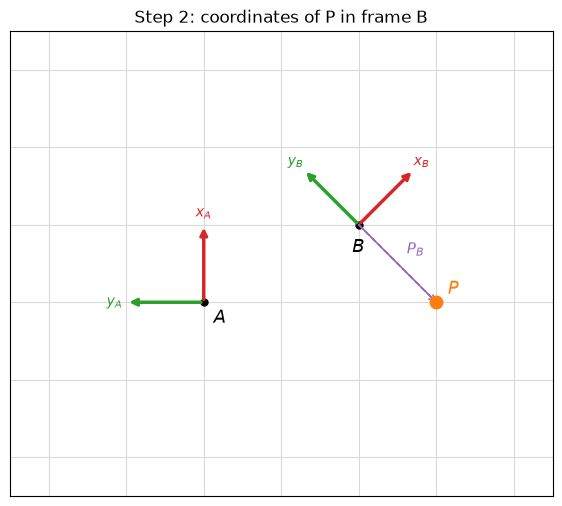

In [9]:
P_B = np.array([0.0, -np.sqrt(2.0)])
print("P_B =", P_B)
assert np.allclose(pose_B.act(P_B), P)  # consistent with the drawing

fig, ax = new_axes("Step 2: coordinates of P in frame B")
draw_frame(ax, pose_A, "A")
draw_frame(ax, pose_B, "B")
draw_point(ax, P)
draw_projection(ax, pose_B, P_B, COLORS["B"])
draw_vector(ax, pose_B.translation, P, color=COLORS["B"], label="$P_B$")
plt.show()

## Step 3: translation part of $T_{AB}$

The translation $t_{AB}$ is the vector from the origin of $A$ to the origin of $B$, **expressed in $A$**.

Read it off the drawing by counting squares along the axes of $A$: from $A$ we go 1 square along $x_A$ (up) and 2 squares against $y_A$ (i.e. to the right), so

$$ t_{AB} = (1, -2). $$

The dashed frame $A'$ is frame $A$ translated to the origin of $B$ while keeping its orientation. It is what we get after applying only the translation part.

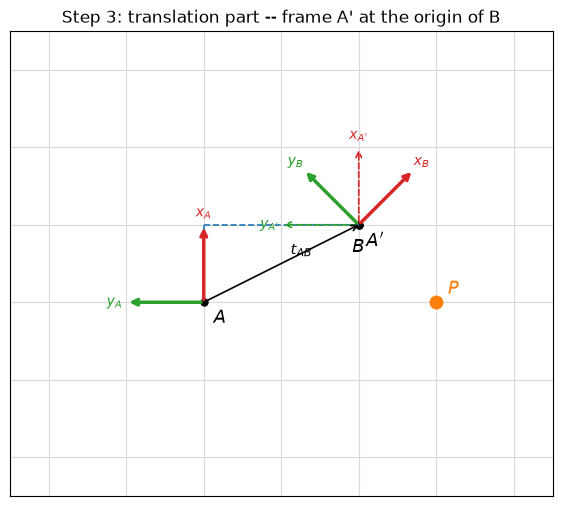

In [10]:
t_AB = np.array([1.0, -2.0])
assert np.allclose(pose_A.act(t_AB), pose_B.translation)  # consistent with the drawing

# frame A': orientation of A, origin of B
pose_Ap = SE2(translation=pose_B.translation, rotation=pose_A.rotation)

fig, ax = new_axes("Step 3: translation part -- frame A' at the origin of B")
draw_frame(ax, pose_A, "A")
draw_frame(ax, pose_B, "B")
draw_frame(ax, pose_Ap, "A'", lw=1.2, ls="--")
draw_point(ax, P)
draw_projection(ax, pose_A, t_AB, COLORS["A"])
draw_vector(ax, pose_A.translation, pose_B.translation, color=COLORS["A'"], label="$t_{AB}$")
plt.show()

## Step 4: rotation part of $T_{AB}$

$R_{AB}$ rotates the axes of $A'$ onto the axes of $B$. Both frames share the origin now, so we only need the angle between $x_{A'}$ (pointing up) and $x_B$ (pointing top-right), measured counter-clockwise from $A'$ to $B$:

$$ \theta_{AB} = 45^\circ - 90^\circ = -45^\circ \equiv 315^\circ, \qquad R_{AB} = R(\theta_{AB}). $$

Note that `SO2` takes the angle in radians.

theta_AB = -45 deg  (= 315 deg)
R_AB.rot =
 [[ 0.707  0.707]
 [-0.707  0.707]]


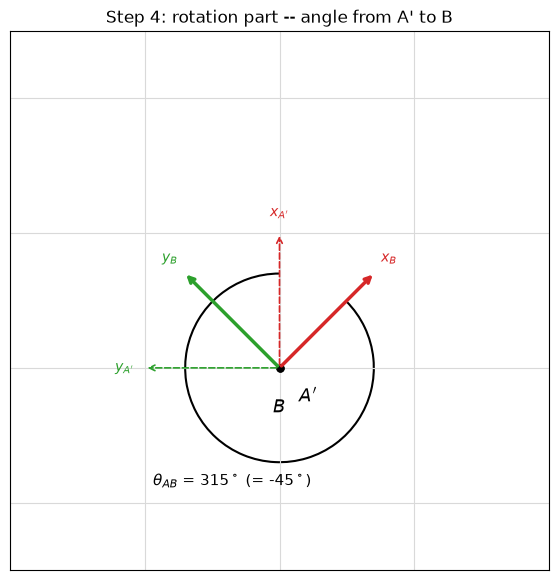

In [11]:
theta_AB = np.deg2rad(45.0 - 90.0)
R_AB = SO2(theta_AB)
print(f"theta_AB = {np.rad2deg(R_AB.angle):.0f} deg  (= {deg(R_AB):.0f} deg)")
print("R_AB.rot =\n", R_AB.rot)

fig, ax = new_axes("Step 4: rotation part -- angle from A' to B", xlim=(0, 4), ylim=(-0.5, 3.5))
draw_frame(ax, pose_Ap, "A'", lw=1.2, ls="--")
draw_frame(ax, pose_B, "B")
draw_angle(ax, pose_B.translation, 90, 45, 0.7, "k", "$\\theta_{AB}$ = 315$^\\circ$ (= -45$^\\circ$)")
plt.show()

## Step 5: assemble $T_{AB}$ and transform $P$

$$ T_{AB} = \begin{bmatrix} R_{AB} & t_{AB} \\ 0 & 1 \end{bmatrix}
= \begin{bmatrix} \cos(-45^\circ) & -\sin(-45^\circ) & 1 \\ \sin(-45^\circ) & \cos(-45^\circ) & -2 \\ 0 & 0 & 1 \end{bmatrix} .$$

$T_{AB}$ maps coordinates from $B$ to $A$. We have $P_B$ and want $P_A$, so we apply it directly:

$$ P_A = T_{AB} \begin{bmatrix} P_B \\ 1 \end{bmatrix} = R_{AB} P_B + t_{AB} . $$

Check against the drawing: $P$ lies 3 squares to the right of the origin of $A$. The $y_A$ axis points to the left, so "right" is $-y_A$, hence $P_A = (0, -3)$.

T_AB = SE2(translation=[ 1. -2.], rotation=SO2(-0.7853981633974483))
T_AB.homogeneous() =
 [[ 0.707  0.707  1.   ]
 [-0.707  0.707 -2.   ]
 [ 0.     0.     1.   ]]
P_A = T_AB.act(P_B) = [ 0. -3.]
T_AB.homogeneous() @ [P_B; 1] = [ 0. -3.  1.]
matches the drawing


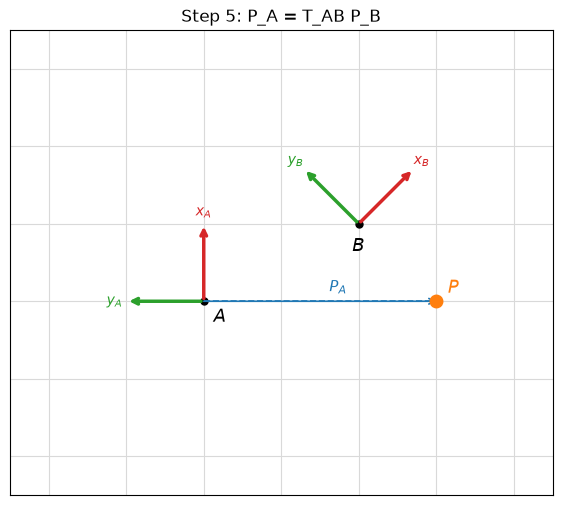

In [12]:
T_AB = SE2(translation=t_AB, rotation=R_AB)
P_A = T_AB.act(P_B)

print("T_AB =", T_AB)
print("T_AB.homogeneous() =\n", T_AB.homogeneous())
print("P_A = T_AB.act(P_B) =", P_A)
# the same thing written out with the homogeneous matrix:
print("T_AB.homogeneous() @ [P_B; 1] =", T_AB.homogeneous() @ np.append(P_B, 1.0))
assert np.allclose(pose_A.act(P_A), P)  # consistent with the drawing
print("matches the drawing")

fig, ax = new_axes("Step 5: P_A = T_AB P_B")
draw_frame(ax, pose_A, "A")
draw_frame(ax, pose_B, "B")
draw_point(ax, P)
draw_projection(ax, pose_A, P_A, COLORS["A"])
draw_vector(ax, pose_A.translation, P, color=COLORS["A"], label="$P_A$")
plt.show()

## Play with it

Move frames $A$ and $B$ around on the grid and watch how $T_{AB}$, $P_B$ and $P_A = T_{AB} P_B$ change. Moving only $B$ leaves $P_A$ untouched, moving only $A$ leaves $P_B$ untouched. Uses `ipywidgets` sliders when they are installed (`uv pip install ipywidgets`), otherwise call `explore(...)` with your own values.


In [ ]:
from IPython.display import display


def explore(a_x=0.0, a_y=0.0, theta_A=90.0, b_x=2.0, b_y=1.0, theta_B=45.0):
    pose_A = SE2(translation=[a_x, a_y], rotation=SO2(np.deg2rad(theta_A)))
    pose_B = SE2(translation=[b_x, b_y], rotation=SO2(np.deg2rad(theta_B)))
    # relative pose of B in A and coordinates of P in B, obtained from the grid poses
    T_AB = pose_A.inverse() * pose_B
    P_B = pose_B.inverse().act(P)
    P_A = T_AB.act(P_B)
    print(f"t_AB = {T_AB.translation}   theta_AB = {deg(T_AB):.1f} deg")
    print("T_AB.homogeneous() =\n", T_AB.homogeneous())
    print("P_B =", P_B)
    print("P_A = T_AB.act(P_B) =", P_A)

    # Create the figure with interactive mode off and display it explicitly, otherwise
    # the notebook backend shows it a second time when the cell finishes.
    with plt.ioff():
        fig, ax = new_axes(
            f"A at ({a_x:.1f}, {a_y:.1f}), {theta_A:.0f} deg;   B at ({b_x:.1f}, {b_y:.1f}), {theta_B:.0f} deg",
            xlim=(-4, 6),
            ylim=(-4, 5),
        )
    draw_frame(ax, pose_A, "A")
    draw_frame(ax, pose_B, "B")
    draw_point(ax, P)
    draw_projection(ax, pose_A, P_A, COLORS["A"])
    draw_projection(ax, pose_B, P_B, COLORS["B"])
    draw_vector(ax, pose_A.translation, pose_B.translation, color=COLORS["A'"], label="$t_{AB}$")
    draw_vector(ax, pose_A.translation, P, color=COLORS["A"], label="$P_A$")
    draw_vector(ax, pose_B.translation, P, color=COLORS["B"], label="$P_B$")
    display(fig)
    plt.close(fig)


try:
    from ipywidgets import FloatSlider, HBox, Output, VBox

    sliders_A = dict(
        a_x=FloatSlider(0.0, min=-3, max=4, step=0.5, description="A x"),
        a_y=FloatSlider(0.0, min=-3, max=4, step=0.5, description="A y"),
        theta_A=FloatSlider(90.0, min=-180, max=180, step=15, description="A angle"),
    )
    sliders_B = dict(
        b_x=FloatSlider(2.0, min=-3, max=4, step=0.5, description="B x"),
        b_y=FloatSlider(1.0, min=-3, max=4, step=0.5, description="B y"),
        theta_B=FloatSlider(45.0, min=-180, max=180, step=15, description="B angle"),
    )
    sliders = {**sliders_A, **sliders_B}
    out = Output()
    # Show the widgets first and draw into them afterwards. (Calling `interact` directly
    # draws before the output area is on screen, which some frontends render twice.)
    display(HBox([VBox(list(sliders_A.values())), VBox(list(sliders_B.values()))]), out)

    def on_change(_=None):
        with out:
            out.clear_output(wait=True)
            explore(**{k: s.value for k, s in sliders.items()})

    for s in sliders.values():
        s.observe(on_change, names="value")
    on_change()
except ImportError:
    print("ipywidgets not installed -- calling explore() with default values instead.")
    explore()
